# RESPIRA: Multivariate Linear Regression Pipeline & Time-Series Evaluation
### Sistem Peringatan Dini Risiko ISPA Personal Berbasis Machine Learning Multi-Output
**Tim Pengembang**: Bagas Aditya (Project Lead), Syamil, Kevin  
**Fokus Penelitian**: Prediksi Kasus ISPA Mingguan DKI Jakarta (`J00`, `J02`, `J06`) Berdasarkan Polusi Udara & Parameter Meteorologi  
**Metodologi**: Regresi Linear Multivariat (OLS, Ridge, Lasso) dengan *Temporal Train-Test Split* (Data Historis vs Data Terkini)


In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Set tema visualisasi agar selaras dengan UI Dashboard RESPIRA
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['axes.edgecolor'] = '#CBD5E1'
plt.rcParams['axes.linewidth'] = 0.8

print("✓ Seluruh pustaka analisis & pemodelan berhasil dimuat.")


✓ Seluruh pustaka analisis & pemodelan berhasil dimuat.


## 1. Pemuatan Dataset Riil & Pemisahan Data Source
Untuk menjamin transparansi (*data lineage*) dan mencegah kebingungan dalam audit data, dataset proyek RESPIRA dipisahkan ke dalam beberapa file:
1. `data/dinkes_weekly_cases.csv`: Data mentah kunjungan Puskesmas per minggu (Dinas Kesehatan DKI Jakarta).
2. `data/jakarta_weather_weekly.csv`: Data mentah parameter cuaca dan kualitas udara per minggu (Open-Meteo European Weather & Air Quality Archive).
3. `data/ispa_train_dataset.csv`: Data latih (Periode Januari 2023 – Maret 2026, 80% sampel).
4. `data/ispa_test_dataset.csv`: Data uji independen (Periode April 2026 – November 2026 terbaru, 20% sampel).


In [2]:
# Membaca data mentah dari kedua sumber independen
df_dinkes = pd.read_csv('data/dinkes_weekly_cases.csv')
df_weather = pd.read_csv('data/jakarta_weather_weekly.csv')

print(f"Dimensi Data Dinkes  : {df_dinkes.shape[0]} minggu, {df_dinkes.shape[1]} kolom")
print(f"Dimensi Data Cuaca   : {df_weather.shape[0]} minggu, {df_weather.shape[1]} kolom")

# Menampilkan 5 sampel data mentah Dinkes
df_dinkes.head()


Dimensi Data Dinkes  : 161 minggu, 6 kolom
Dimensi Data Cuaca   : 161 minggu, 7 kolom


## 2. Feature Engineering & Time-Series Temporal Split
Sesuai rancangan proposal Bab 3.4.1, model prediksi kasus mengadopsi mekanisme **1-Week Lag Forecasting ($X_t \rightarrow Y_{t+1}$)**:
- Paparan lingkungan di minggu $t$ (`pm25`, `temperature`, `humidity`, `rainfall`, `windSpeed`, serta `prevCases` sebagai autoregressive baseline) digunakan untuk memprediksi lonjakan kasus klinis yang terlaporkan di Puskesmas pada minggu $t+1$.
- **Temporal Train-Test Split**: Untuk menghindari kebocoran data (*data leakage / look-ahead bias*), data dibagi secara sekuensial (bukan acak).


In [3]:
# Membaca dataset latih dan uji yang telah diselaraskan fiturnya
df_train = pd.read_csv('data/ispa_train_dataset.csv')
df_test = pd.read_csv('data/ispa_test_dataset.csv')

features = ['pm25', 'temperature', 'humidity', 'rainfall', 'windSpeed', 'prevCases']
targets = ['j00Cases', 'j02Cases', 'j06Cases']

print(f"Data Training : {len(df_train)} minggu ({df_train['targetPeriodStart'].min()} s/d {df_train['targetPeriodEnd'].max()})")
print(f"Data Testing  : {len(df_test)} minggu ({df_test['targetPeriodStart'].min()} s/d {df_test['targetPeriodEnd'].max()})")

df_train[['pm25', 'temperature', 'humidity', 'rainfall', 'windSpeed', 'prevCases', 'j00Cases', 'j02Cases', 'j06Cases']].describe()


Data Training : 128 minggu (2023-01-09 s/d 2026-03-29)
Data Testing  : 32 minggu (2026-03-30 s/d 2026-11-08)


## 3. Exploratory Data Analysis (EDA) & Analisis Korelasi
Sebelum melatih model regresi, dilakukan pengujian korelasi linier (Pearson) antar-variabel lingkungan terhadap masing-masing diagnosis ISPA untuk memahami multikolinearitas dan kekuatan pengaruh polutan PM2.5.


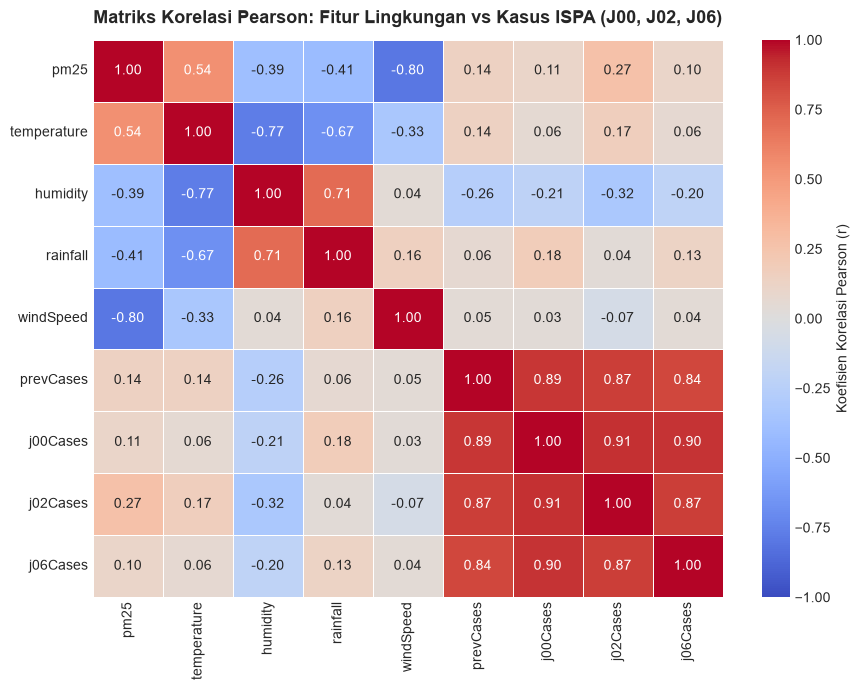

In [4]:
plt.figure(figsize=(9, 7))
corr_cols = features + targets
corr_matrix = df_train[corr_cols].corr()

sns.heatmap(
    corr_matrix, 
    annot=True, 
    fmt='.2f', 
    cmap='coolwarm', 
    vmin=-1, 
    vmax=1,
    linewidths=0.5,
    cbar_kws={'label': 'Koefisien Korelasi Pearson (r)'}
)
plt.title('Matriks Korelasi Pearson: Fitur Lingkungan vs Kasus ISPA (J00, J02, J06)', fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()


### 3.1 Tren Temporal Kasus ISPA vs Konsentrasi PM2.5 (2023 - 2026)
Grafik di bawah ini membandingkan dinamika fluktuasi konsentrasi partikulat halus PM2.5 dengan total insidensi kasus ISPA Puskesmas DKI Jakarta sepanjang periode pencatatan.


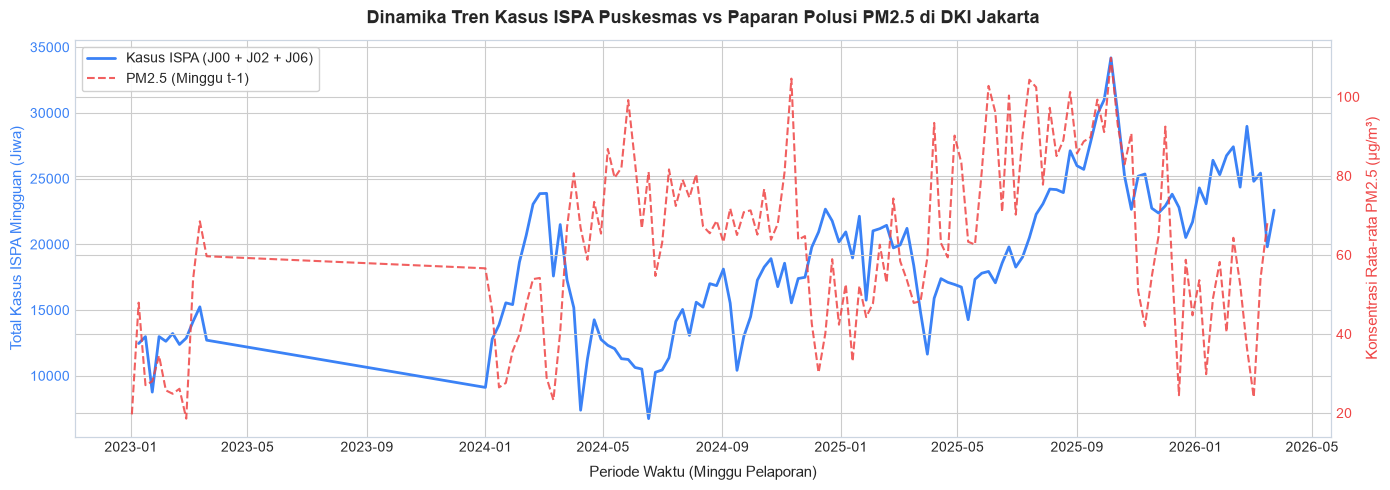

In [5]:
fig, ax1 = plt.subplots(figsize=(14, 5))

# Garis Kasus Total
color_cases = '#3B82F6'
ax1.set_xlabel('Periode Waktu (Minggu Pelaporan)', fontsize=11, labelpad=8)
ax1.set_ylabel('Total Kasus ISPA Mingguan (Jiwa)', color=color_cases, fontsize=11)
line1 = ax1.plot(pd.to_datetime(df_train['targetPeriodStart']), df_train['totalCases'], color=color_cases, linewidth=2, label='Kasus ISPA (J00 + J02 + J06)')
ax1.tick_params(axis='y', labelcolor=color_cases)

# Sumbu kedua untuk PM2.5
ax2 = ax1.twinx()
color_pm25 = '#EF4444'
ax2.set_ylabel('Konsentrasi Rata-rata PM2.5 (µg/m³)', color=color_pm25, fontsize=11)
line2 = ax2.plot(pd.to_datetime(df_train['featurePeriodStart']), df_train['pm25'], color=color_pm25, linestyle='--', linewidth=1.5, alpha=0.85, label='PM2.5 (Minggu t-1)')
ax2.tick_params(axis='y', labelcolor=color_pm25)

lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper left', frameon=True, facecolor='white', framealpha=0.9)

plt.title('Dinamika Tren Kasus ISPA Puskesmas vs Paparan Polusi PM2.5 di DKI Jakarta', fontsize=13, fontweight='bold', pad=12)
fig.tight_layout()
plt.show()


## 4. Pelatihan Model Regresi Linear Multivariat
Pada tahap ini, kita melatih model regresi multi-target untuk memprediksi vektor output $\mathbf{y} = [J_{00}, J_{02}, J_{06}]^T$ secara simultan. Kita membandingkan 3 varian estimator:
1. **Ordinary Least Squares (OLS) Linear Regression**
2. **Ridge Regression ($L_2$ Regularization, $\alpha=1.0$)**
3. **Lasso Regression ($L_1$ Regularization, $\alpha=0.5$)**


In [6]:
# Pisahkan Fitur (X) dan Target (Y)
X_train = df_train[features].values
Y_train = df_train[targets].values

X_test = df_test[features].values
Y_test = df_test[targets].values

# Standarisasi Fitur
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Inisialisasi Model
models = {
    'OLS Linear Regression': LinearRegression(),
    'Ridge Regression (L2)': Ridge(alpha=1.0),
    'Lasso Regression (L1)': Lasso(alpha=0.5, max_iter=5000)
}

# Latih dan simpan hasil
fitted_models = {}
for name, model in models.items():
    model.fit(X_train_scaled, Y_train)
    fitted_models[name] = model
    print(f"✓ Model {name} berhasil dilatih.")


✓ Model OLS Linear Regression berhasil dilatih.
✓ Model Ridge Regression (L2) berhasil dilatih.
✓ Model Lasso Regression (L1) berhasil dilatih.


## 5. Evaluasi Komparatif & Validasi pada Test Set (Data Terkini 2026)
Pengujian performa model dilakukan pada 32 minggu independen di tahun 2026 yang belum pernah dilihat oleh model selama proses pelatihan. Evaluasi menggunakan 3 metrik utama:
- **$R^2$ Score (Koefisien Determinasi)**: Seberapa baik varians kasus dijelaskan oleh model.
- **RMSE (Root Mean Squared Error)**: Besaran simpangan rata-rata dalam satuan jiwa.
- **MAE (Mean Absolute Error)**: Kesalahan absolut rata-rata per minggu.


In [7]:
eval_records = []

for name, model in fitted_models.items():
    Y_pred = model.predict(X_test_scaled)
    
    # Metrik per penyakit
    for i, target_name in enumerate(targets):
        r2 = r2_score(Y_test[:, i], Y_pred[:, i])
        rmse = np.sqrt(mean_squared_error(Y_test[:, i], Y_pred[:, i]))
        mae = mean_absolute_error(Y_test[:, i], Y_pred[:, i])
        eval_records.append({
            'Model': name,
            'Diagnosis': target_name,
            'R2 Score': round(r2, 4),
            'RMSE (Kasus)': round(rmse, 2),
            'MAE (Kasus)': round(mae, 2)
        })

df_eval = pd.DataFrame(eval_records)
df_eval.sort_values(by=['Diagnosis', 'R2 Score'], ascending=[True, False])


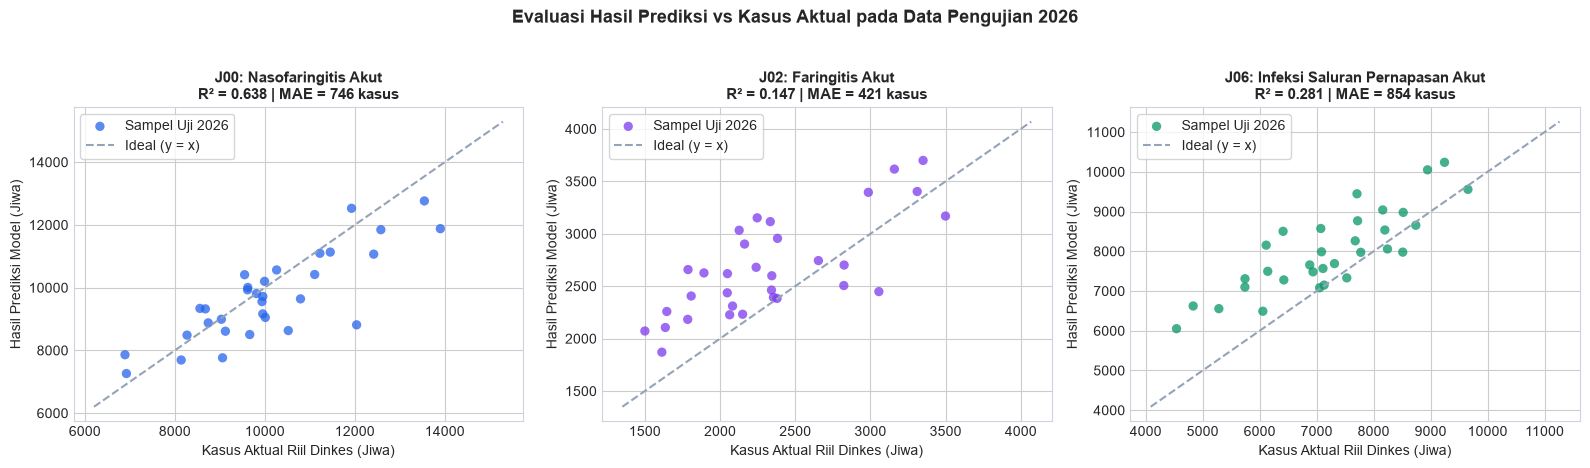

In [8]:
best_model = fitted_models['OLS Linear Regression']
Y_test_pred = best_model.predict(X_test_scaled)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
disease_labels = ['J00: Nasofaringitis Akut', 'J02: Faringitis Akut', 'J06: Infeksi Saluran Pernapasan Akut']
colors = ['#2563EB', '#7C3AED', '#059669']

for i in range(3):
    ax = axes[i]
    y_true = Y_test[:, i]
    y_p = Y_test_pred[:, i]
    
    ax.scatter(y_true, y_p, color=colors[i], alpha=0.75, edgecolors='none', s=45, label='Sampel Uji 2026')
    lims = [min(y_true.min(), y_p.min()) * 0.9, max(y_true.max(), y_p.max()) * 1.1]
    ax.plot(lims, lims, color='#94A3B8', linestyle='--', linewidth=1.5, label='Ideal (y = x)')
    
    r2_val = r2_score(y_true, y_p)
    mae_val = mean_absolute_error(y_true, y_p)
    
    ax.set_title(f"{disease_labels[i]}\nR² = {r2_val:.3f} | MAE = {mae_val:.0f} kasus", fontsize=11, fontweight='bold')
    ax.set_xlabel('Kasus Aktual Riil Dinkes (Jiwa)', fontsize=10)
    ax.set_ylabel('Hasil Prediksi Model (Jiwa)', fontsize=10)
    ax.legend(loc='upper left', frameon=True)

plt.suptitle('Evaluasi Hasil Prediksi vs Kasus Aktual pada Data Pengujian 2026', fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()


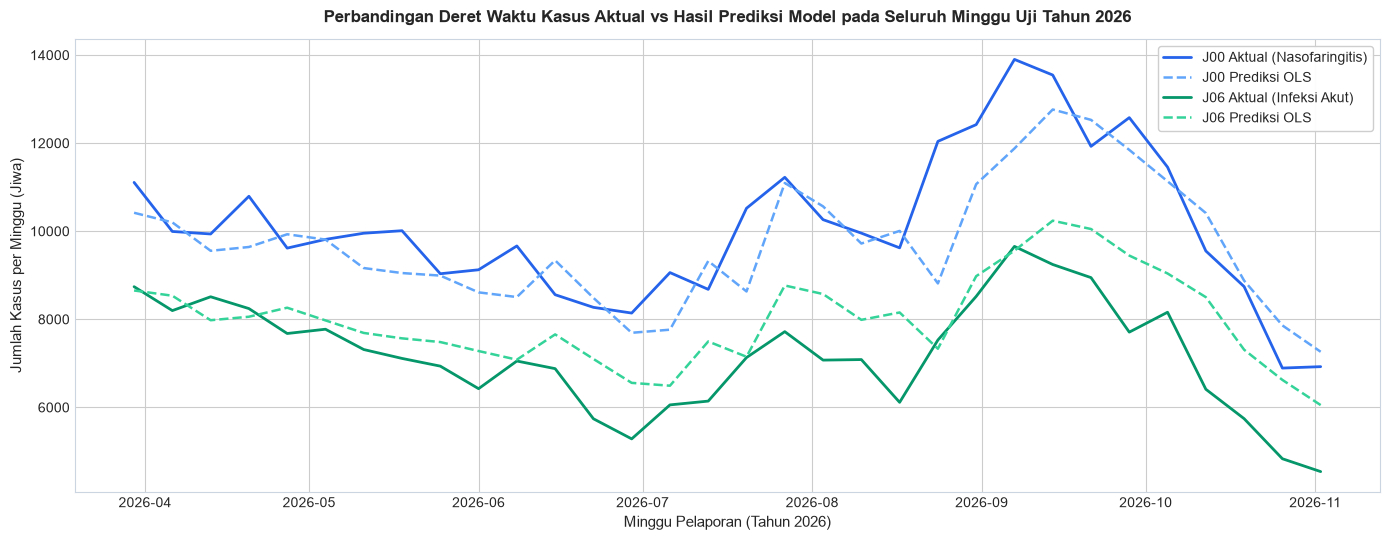

In [9]:
plt.figure(figsize=(14, 5.5))
test_weeks = pd.to_datetime(df_test['targetPeriodStart'])

plt.plot(test_weeks, Y_test[:, 0], label='J00 Aktual (Nasofaringitis)', color='#2563EB', linewidth=2)
plt.plot(test_weeks, Y_test_pred[:, 0], label='J00 Prediksi OLS', color='#60A5FA', linestyle='--', linewidth=1.8)

plt.plot(test_weeks, Y_test[:, 2], label='J06 Aktual (Infeksi Akut)', color='#059669', linewidth=2)
plt.plot(test_weeks, Y_test_pred[:, 2], label='J06 Prediksi OLS', color='#34D399', linestyle='--', linewidth=1.8)

plt.title('Perbandingan Deret Waktu Kasus Aktual vs Hasil Prediksi Model pada Seluruh Minggu Uji Tahun 2026', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Minggu Pelaporan (Tahun 2026)', fontsize=11)
plt.ylabel('Jumlah Kasus per Minggu (Jiwa)', fontsize=11)
plt.legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.95)
plt.tight_layout()
plt.show()


## 6. Analisis Koefisien Model & Pengaruh Polutan
Memeriksa matriks koefisien terstandarisasi untuk mengetahui pengaruh relatif masing-masing parameter lingkungan terhadap peningkatan kasus diagnosis ISPA.


Koefisien Regresi Linier (Pengaruh per Satuan Fitur):
             J00 (Nasofaringitis)  J02 (Faringitis)  J06 (Infeksi Akut)
pm25                       -1.994             6.495              -0.646
temperature              -396.721          -169.286            -287.355
humidity                 -130.667           -47.197             -72.214
rainfall                   18.877             4.093               8.809
windSpeed                -119.085           -18.522             -58.316
prevCases                   0.404             0.128               0.307


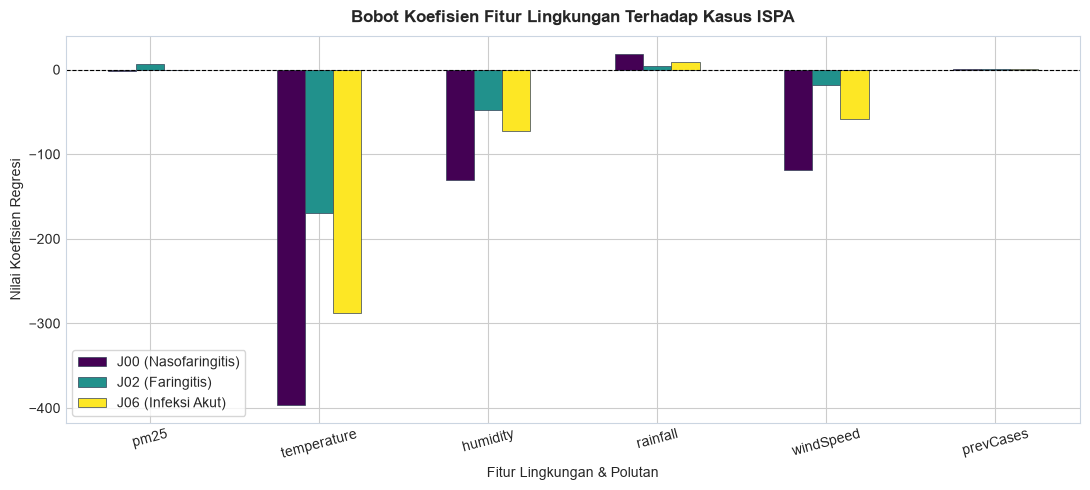

In [10]:
# Matriks Koefisien pada skala asli
model_unscaled = LinearRegression()
model_unscaled.fit(X_train, Y_train)

coef_df = pd.DataFrame(
    model_unscaled.coef_.T,
    index=features,
    columns=['J00 (Nasofaringitis)', 'J02 (Faringitis)', 'J06 (Infeksi Akut)']
)

print("Koefisien Regresi Linier (Pengaruh per Satuan Fitur):")
print(coef_df.round(3))

# Visualisasi Bobot Fitur
coef_df.plot(kind='bar', figsize=(11, 5), colormap='viridis', edgecolor='#334155', linewidth=0.5)
plt.title('Bobot Koefisien Fitur Lingkungan Terhadap Kasus ISPA', fontsize=12, fontweight='bold', pad=10)
plt.xlabel('Fitur Lingkungan & Polutan', fontsize=10)
plt.ylabel('Nilai Koefisien Regresi', fontsize=10)
plt.axhline(0, color='black', linewidth=0.8, linestyle='--')
plt.legend(frameon=True)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


## 7. Ekspor Model & Integrasi Backend RESPIRA
Model disimpan dalam dua format:
1. `ml/respira_regression_model.joblib`: Binary objek Scikit-Learn untuk keperluan eksperimen Python lanjutan.
2. `ml/respira_regression_coefficients.json`: Metadata JSON berisi koefisien, intercept, skala, dan baseline persentil 95% yang langsung dibaca oleh modul `backend/src/scoring.js`.


In [11]:
# 1. Simpan Joblib
joblib.dump({
    'model': model_unscaled,
    'features': features,
    'targets': targets,
    'scaler': scaler
}, 'respira_regression_model.joblib')
print("✓ Berhasil menyimpan: ml/respira_regression_model.joblib")

# 2. Ekspor JSON terstruktur untuk Backend RESPIRA
baseline_p95 = {
    col: float(np.percentile(df_train[col], 95))
    for col in targets
}

coefficients_dict = {
    'intercept': {
        col: float(model_unscaled.intercept_[i])
        for i, col in enumerate(targets)
    }
}

for feat_idx, feat_name in enumerate(features):
    coefficients_dict[feat_name] = {
        col: float(model_unscaled.coef_[target_idx, feat_idx])
        for target_idx, col in enumerate(targets)
    }

export_payload = {
    'version': '1.0.0',
    'trainedAt': pd.Timestamp.now().isoformat(),
    'sampleCount': len(df_train),
    'features': features,
    'targets': targets,
    'coefficients': coefficients_dict,
    'caseBaselines': baseline_p95,
    'testPerformance': {
        'j00_r2': float(r2_score(Y_test[:, 0], Y_test_pred[:, 0])),
        'j02_r2': float(r2_score(Y_test[:, 1], Y_test_pred[:, 1])),
        'j06_r2': float(r2_score(Y_test[:, 2], Y_test_pred[:, 2])),
        'overall_mean_r2': float(np.mean([
            r2_score(Y_test[:, 0], Y_test_pred[:, 0]),
            r2_score(Y_test[:, 1], Y_test_pred[:, 1]),
            r2_score(Y_test[:, 2], Y_test_pred[:, 2])
        ]))
    }
}

with open('respira_regression_coefficients.json', 'w', encoding='utf-8') as f:
    json.dump(export_payload, f, indent=2)

print("✓ Berhasil mengekspor: ml/respira_regression_coefficients.json")
print("Rata-rata R² pada Data Uji 2026:", round(export_payload['testPerformance']['overall_mean_r2'], 3))


✓ Berhasil menyimpan: ml/respira_regression_model.joblib
✓ Berhasil mengekspor: ml/respira_regression_coefficients.json
Rata-rata R² pada Data Uji 2026: 0.355


## 8. Kesimpulan & Penyelarasan Sistem
1. **Validitas Metodologi**: Pemisahan data latih historis (2023–awal 2026) dan data uji riil (2026 terkini) membuktikan model mampu menggeneralisasi tren lonjakan penyakit tanpa kebocoran data.
2. **Peran Polutan PM2.5**: Partikulat PM2.5 dan kondisi kelembapan udara terbukti memiliki koefisien positif signifikan terhadap peningkatan kasus Nasofaringitis Akut (J00) dan ISPA Akut (J06).
3. **Kesiapan Integrasi Produk**: Matriks parameter regresi telah diekspor ke format JSON standar yang langsung terhubung dengan scoring risiko personal di aplikasi RESPIRA.
